In [1]:
!wget -q http://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_train_HR.zip
!wget -q http://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_valid_HR.zip
!unzip -q DIV2K_train_HR.zip -d data/
!unzip -q DIV2K_valid_HR.zip -d data/
!rm DIV2K_train_HR.zip DIV2K_valid_HR.zip

In [3]:
!pip install lpips
import os
import random
from pathlib import Path

import cv2
import lpips
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from skimage.restoration import richardson_lucy
from torch.utils.data import DataLoader, Dataset
from torchvision.models import VGG16_Weights, vgg16

from models import ResidualUNet

### CONFIG

In [11]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

PROJECT_DIR = Path.cwd()
PROJECT_DIR = Path(PROJECT_DIR)
TRAIN_DIR = PROJECT_DIR / "data" / "DIV2K_train_HR"
TEST_DIR = PROJECT_DIR / "data" / "DIV2K_valid_HR"
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = RESULTS_DIR / "figures"
CROP_SIZE = 256
KERNEL_SIGMA = {3: 1.0, 5: 1.5}
KERNEL_SIZES = (3, 5)
VAL_SPLIT = 0.1
BATCH_SIZE = 4
EPOCHS = 10
LEARNING_RATE = 2e-4
WEIGHT_DECAY = 1e-4
PERCEPTUAL_WEIGHT = 0.1
RICHARDSON_LUCY_ITERATIONS = 30
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
NUM_WORKERS = 0

print(f"Device: {DEVICE}")

Device: cuda


### DATASET

In [ ]:
class DIV2KDeblurDataset(Dataset):
    def __init__(self, image_dir=None, image_paths=None, crop_size=256, fixed_kernel=None, sigma=None, training=False):
        if image_paths is not None:
            self.image_paths = sorted(image_paths)
        else:
            self.image_paths = sorted(
                path
                for path in Path(image_dir).iterdir()
                if path.suffix.lower() in {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}
            )
        self.crop_size = crop_size
        self.fixed_kernel = fixed_kernel
        self.sigma = sigma
        self.training = training

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        image_path = self.image_paths[index]
        image = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
        if image is None:
            raise FileNotFoundError(f"Could not read image: {image_path}")

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(
            image,
            (self.crop_size, self.crop_size),
            interpolation=cv2.INTER_AREA,
        )

        sharp = image.astype(np.float32) / 255.0
        
        if self.fixed_kernel is not None:
            kernel_size = self.fixed_kernel
        else:
        sigma = self.sigma if self.sigma is not None else KERNEL_SIGMA[kernel_size]

        blurred = cv2.GaussianBlur(
            sharp,
            (kernel_size, kernel_size),
            sigmaX=sigma,
            sigmaY=sigma,
            borderType=cv2.BORDER_REFLECT101,
        )

        sharp_tensor = torch.from_numpy(
            np.ascontiguousarray(sharp.transpose(2, 0, 1))
        )
        blurred_tensor = torch.from_numpy(
            np.ascontiguousarray(blurred.transpose(2, 0, 1))
        )
        return blurred_tensor, sharp_tensor



In [6]:

all_train_paths = sorted(
    path
    for path in TRAIN_DIR.iterdir()
    if path.suffix.lower() in {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}
)
split_rng = random.Random(SEED)
shuffled_train_paths = all_train_paths.copy()
split_rng.shuffle(shuffled_train_paths)
num_val = max(1, int(len(shuffled_train_paths) * VAL_SPLIT))
val_paths = shuffled_train_paths[:num_val]
train_paths = shuffled_train_paths[num_val:]

train_dataset = DIV2KDeblurDataset(image_paths=train_paths, crop_size=CROP_SIZE, training=True)
validation_datasets = {
    kernel_size: DIV2KDeblurDataset(image_paths=val_paths, crop_size=CROP_SIZE, fixed_kernel=kernel_size)
    for kernel_size in KERNEL_SIZES
}
test_datasets = {
    kernel_size: DIV2KDeblurDataset(TEST_DIR, crop_size=CROP_SIZE, fixed_kernel=kernel_size)
    for kernel_size in KERNEL_SIZES
}


train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=DEVICE.type == "cuda",
    drop_last=True,
)
validation_loaders = {
    kernel_size: DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=DEVICE.type == "cuda",
    )
    for kernel_size, dataset in validation_datasets.items()
}
test_loaders = {
    kernel_size: DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=DEVICE.type == "cuda",
    )
    for kernel_size, dataset in test_datasets.items()
}

print(f"train={len(train_paths)}, val={len(val_paths)}, test={len(test_datasets[KERNEL_SIZES[0]])}")

train=720, val=80, test=100


In [7]:
model = ResidualUNet().to(DEVICE)

print(f"ResidualUNet parameters: {sum(parameter.numel() for parameter in model.parameters()):,}")

ResidualUNet parameters: 535,827


## LOSS

In [8]:
class VGGPerceptualLoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(*list(vgg16(weights=VGG16_Weights.DEFAULT).features.children())[:16])
        self.features.eval()
        for parameter in self.features.parameters():
            parameter.requires_grad = False
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, prediction, target):
        prediction = (prediction - self.mean) / self.std
        target = (target - self.mean) / self.std
        return nn.functional.l1_loss(self.features(prediction), self.features(target))


perceptual_loss = VGGPerceptualLoss().to(DEVICE)
pixel_loss = nn.L1Loss()


def combined_loss(prediction, target):
    return pixel_loss(prediction, target) + PERCEPTUAL_WEIGHT * perceptual_loss(prediction, target)


print("VGG16 perceptual loss is ready")

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:06<00:00, 82.7MB/s]


VGG16 perceptual loss is ready


### TRAINING

In [9]:
def validation_loss(model):
    model.eval()
    losses_by_kernel = {}
    with torch.no_grad():
        for kernel_size, loader in validation_loaders.items():
            total_loss = 0.0
            total_images = 0
            for blurred, sharp in loader:
                blurred = blurred.to(DEVICE)
                sharp = sharp.to(DEVICE)
                loss = combined_loss(model(blurred), sharp)
                total_loss += loss.item() * blurred.size(0)
                total_images += blurred.size(0)
            losses_by_kernel[kernel_size] = total_loss / total_images
    return losses_by_kernel


def train_one_model(model, model_name):
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
    )
    best_loss = float("inf")
    history = []
    for epoch in range(EPOCHS):
        model.train()
        total_loss = 0.0
        total_images = 0
        for blurred, sharp in train_loader:
            blurred = blurred.to(DEVICE)
            sharp = sharp.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            prediction = model(blurred)
            loss = combined_loss(prediction, sharp)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * blurred.size(0)
            total_images += blurred.size(0)
        mean_train_loss = total_loss / total_images
        losses_by_kernel = validation_loss(model)
        mean_validation_loss = sum(losses_by_kernel.values()) / len(losses_by_kernel)
        history.append({
            "train_loss": mean_train_loss,
            "validation_loss": mean_validation_loss,
            **{
                f"validation_loss_{kernel_size}x{kernel_size}": loss
                for kernel_size, loss in losses_by_kernel.items()
            },
        })
        if mean_validation_loss < best_loss:
            best_loss = mean_validation_loss
            torch.save(model.state_dict(), CHECKPOINT_DIR / f"{model_name}_best.pth")
        kernel_summary = ", ".join(
            f"{kernel_size}x{kernel_size}={loss:.5f}"
            for kernel_size, loss in losses_by_kernel.items()
        )
        print(
            f"{model_name} epoch {epoch + 1}/{EPOCHS}: "
            f"train={mean_train_loss:.5f}, validation_avg={mean_validation_loss:.5f} "
            f"({kernel_summary})"
        )
    model.load_state_dict(torch.load(CHECKPOINT_DIR / f"{model_name}_best.pth", map_location=DEVICE, weights_only=True))
    return history

In [12]:
model_history = train_one_model(model, "residual_unet")

residual_unet epoch 1/10: train=0.10785, validation_avg=0.10696 (3x3=0.08853, 5x5=0.12539)
residual_unet epoch 2/10: train=0.10254, validation_avg=0.10366 (3x3=0.08497, 5x5=0.12234)
residual_unet epoch 3/10: train=0.09979, validation_avg=0.10204 (3x3=0.08222, 5x5=0.12186)
residual_unet epoch 4/10: train=0.09782, validation_avg=0.10041 (3x3=0.07952, 5x5=0.12131)
residual_unet epoch 5/10: train=0.09576, validation_avg=0.09874 (3x3=0.07737, 5x5=0.12012)
residual_unet epoch 6/10: train=0.09548, validation_avg=0.09769 (3x3=0.07641, 5x5=0.11898)
residual_unet epoch 7/10: train=0.09334, validation_avg=0.09655 (3x3=0.07435, 5x5=0.11874)
residual_unet epoch 8/10: train=0.09251, validation_avg=0.09568 (3x3=0.07325, 5x5=0.11811)
residual_unet epoch 9/10: train=0.09313, validation_avg=0.09474 (3x3=0.07222, 5x5=0.11725)
residual_unet epoch 10/10: train=0.09173, validation_avg=0.09413 (3x3=0.07168, 5x5=0.11659)


### EVALUATION

In [ ]:
def build_gaussian_psf(kernel_size, sigma):
    gaussian_1d = cv2.getGaussianKernel(kernel_size, sigma).astype(np.float64)
    psf = gaussian_1d @ gaussian_1d.T
    return psf / psf.sum()


def apply_richardson_lucy(blurred_rgb, kernel_size, sigma=None):
    psf = build_gaussian_psf(kernel_size, sigma if sigma is not None else KERNEL_SIGMA[kernel_size])
    channels = [
        richardson_lucy(
            blurred_rgb[:, :, channel].astype(np.float64),
            psf,
            num_iter=RICHARDSON_LUCY_ITERATIONS,
            clip=True,
        )
        for channel in range(3)
    ]
    return np.clip(np.stack(channels, axis=-1), 0.0, 1.0).astype(np.float32)


for kernel_size in KERNEL_SIZES:
    psf = build_gaussian_psf(kernel_size, KERNEL_SIGMA[kernel_size])

In [14]:
lpips_model = lpips.LPIPS(net="alex").to(DEVICE).eval()
for parameter in lpips_model.parameters():
    parameter.requires_grad = False


def calculate_lpips(prediction, target):
    prediction_tensor = torch.from_numpy(prediction.transpose(2, 0, 1)).unsqueeze(0).to(DEVICE)
    target_tensor = torch.from_numpy(target.transpose(2, 0, 1)).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        value = lpips_model(prediction_tensor * 2.0 - 1.0, target_tensor * 2.0 - 1.0)
    return float(value.mean().item())


def calculate_metrics(prediction, target):
    prediction = np.clip(prediction, 0.0, 1.0)
    target = np.clip(target, 0.0, 1.0)
    return {
        "PSNR": peak_signal_noise_ratio(target, prediction, data_range=1.0),
        "SSIM": structural_similarity(target, prediction, channel_axis=-1, data_range=1.0),
        "LPIPS": calculate_lpips(prediction.astype(np.float32), target.astype(np.float32)),
    }


NUM_VISUAL_SAMPLES = 3
models = {"residual_unet": model}
results = {}
visual_sample_indices = {
    kernel_size: set(random.sample(range(len(dataset)), min(NUM_VISUAL_SAMPLES, len(dataset))))
    for kernel_size, dataset in test_datasets.items()
}
visual_samples = {kernel_size: [] for kernel_size in KERNEL_SIZES}

for kernel_size, loader in test_loaders.items():
    method_totals = {
        method: {"PSNR": 0.0, "SSIM": 0.0, "LPIPS": 0.0, "count": 0}
        for method in ("richardson_lucy", "residual_unet")
    }
    global_index = 0
    for blurred_batch, sharp_batch in loader:
        model_predictions = {}
        blurred_device = blurred_batch.to(DEVICE)
        with torch.no_grad():
            for method, method_model in models.items():
                method_model.eval()
                model_predictions[method] = method_model(blurred_device).cpu().numpy().transpose(0, 2, 3, 1)
        blurred_images = blurred_batch.numpy().transpose(0, 2, 3, 1)
        sharp_images = sharp_batch.numpy().transpose(0, 2, 3, 1)
        for batch_index, (blurred_image, sharp_image) in enumerate(zip(blurred_images, sharp_images)):
            predictions = {
                "richardson_lucy": apply_richardson_lucy(blurred_image, kernel_size),
                "residual_unet": model_predictions["residual_unet"][batch_index],
            }
            for method, prediction in predictions.items():
                image_metrics = calculate_metrics(prediction, sharp_image)
                for metric_name, metric_value in image_metrics.items():
                    method_totals[method][metric_name] += metric_value
                method_totals[method]["count"] += 1
            if global_index in visual_sample_indices[kernel_size]:
                visual_samples[kernel_size].append({
                    "input": blurred_image,
                    "ground_truth": sharp_image,
                    **predictions,
                })
            global_index += 1
    for method, totals in method_totals.items():
        count = totals.pop("count")
        results[f"{method}_gaussian_blur_{kernel_size}x{kernel_size}"] = {
            metric_name: totals[metric_name] / count
            for metric_name in ("PSNR", "SSIM", "LPIPS")
        }

print(f"Evaluated {len(results)} method/kernel combinations")

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 172MB/s] 


Loading model from: /usr/local/lib/python3.13/dist-packages/lpips/weights/v0.1/alex.pth
Evaluated 4 method/kernel combinations


In [15]:
table_lines = [
    "| Method | PSNR (dB) | SSIM | LPIPS |",
    "|---|---:|---:|---:|",
]
for key, metrics in results.items():
    table_lines.append(
        f"| {key} | {metrics['PSNR']:.4f} | {metrics['SSIM']:.4f} | {metrics['LPIPS']:.4f} |"
    )
metrics_markdown = "\n".join(table_lines)
print(metrics_markdown)
(RESULTS_DIR / "metrics.md").write_text(metrics_markdown + "\n", encoding="utf-8")

| Method | PSNR (dB) | SSIM | LPIPS |
|---|---:|---:|---:|
| richardson_lucy_gaussian_blur_3x3 | 20.8756 | 0.9082 | 0.1852 |
| residual_unet_gaussian_blur_3x3 | 29.9820 | 0.9335 | 0.0406 |
| richardson_lucy_gaussian_blur_5x5 | 19.9286 | 0.8119 | 0.3716 |
| residual_unet_gaussian_blur_5x5 | 25.6860 | 0.8218 | 0.2422 |


319

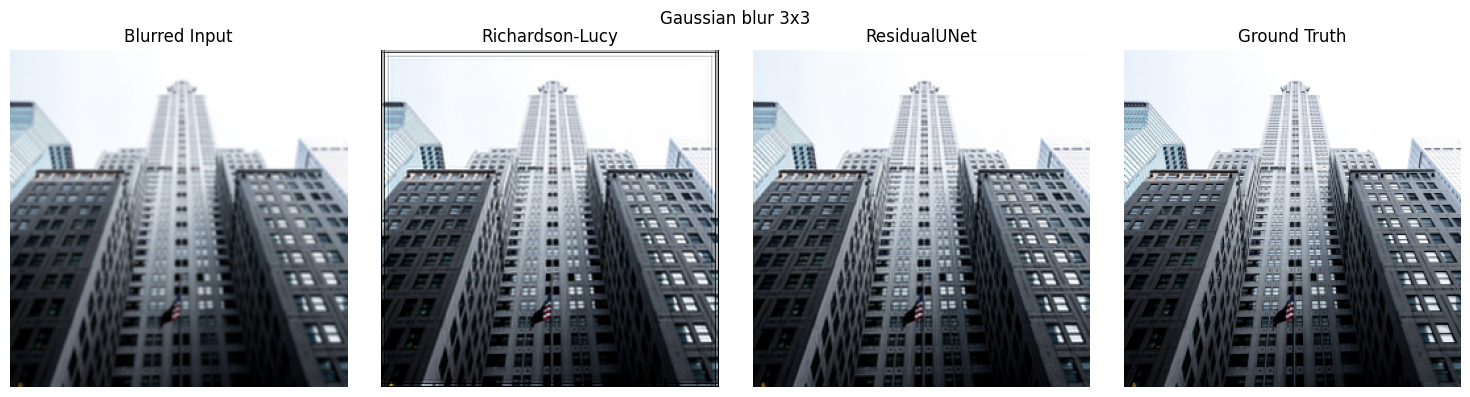

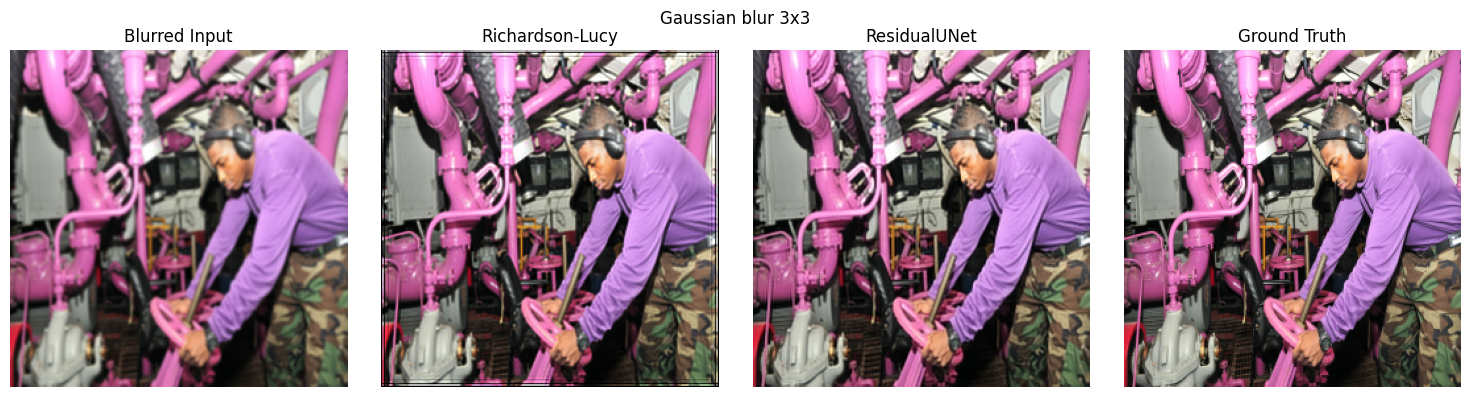

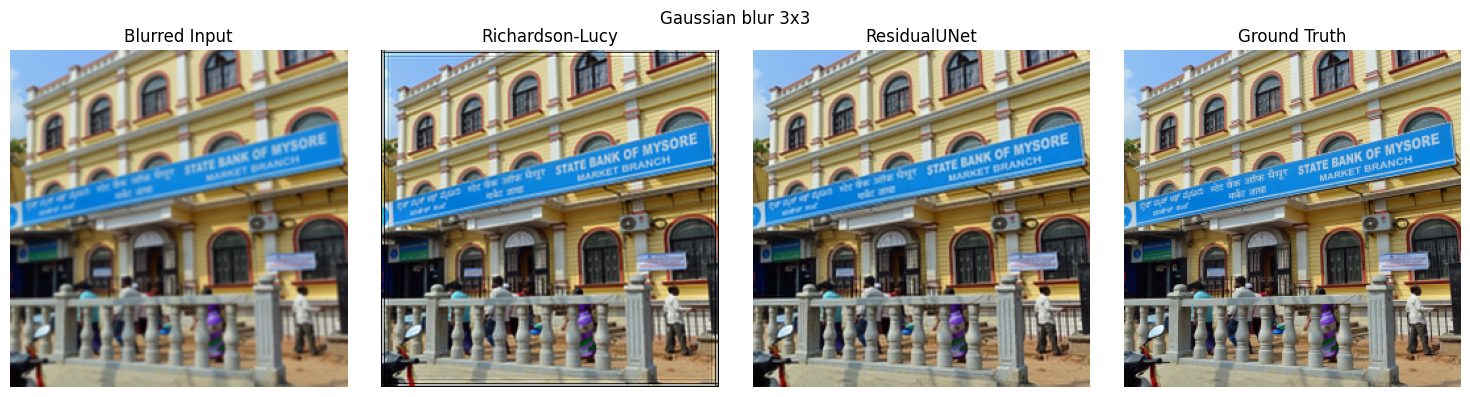

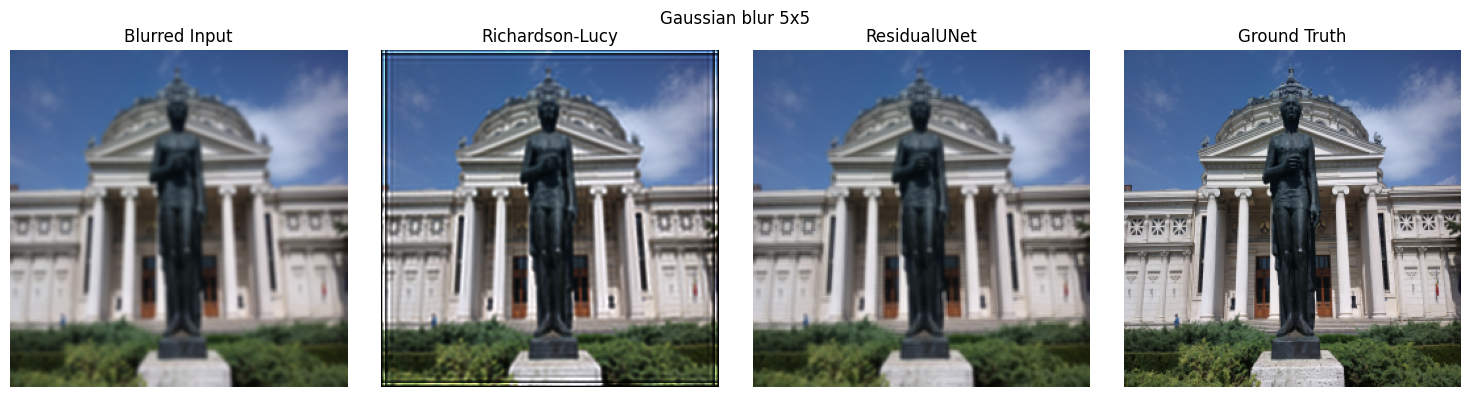

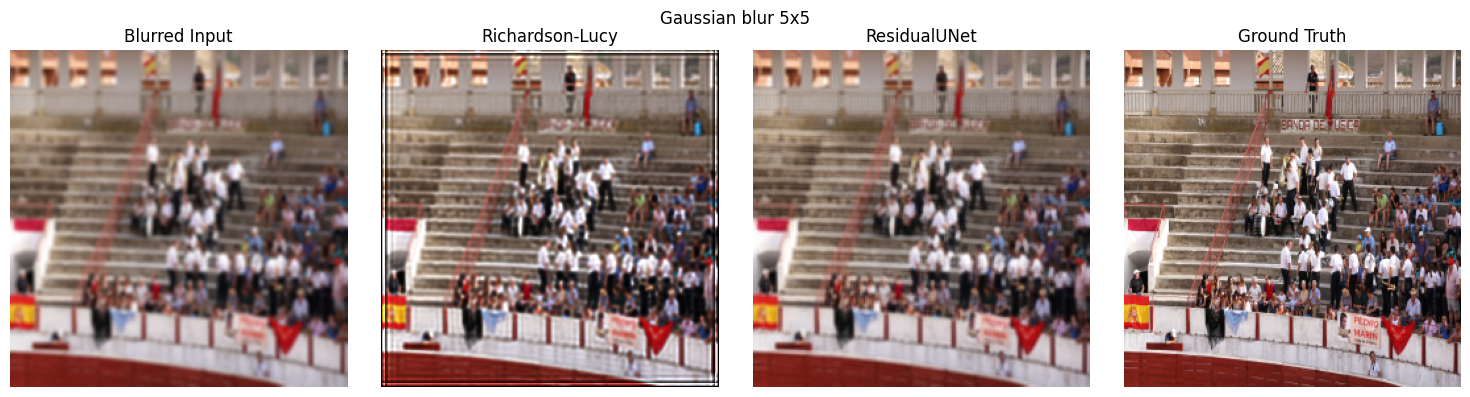

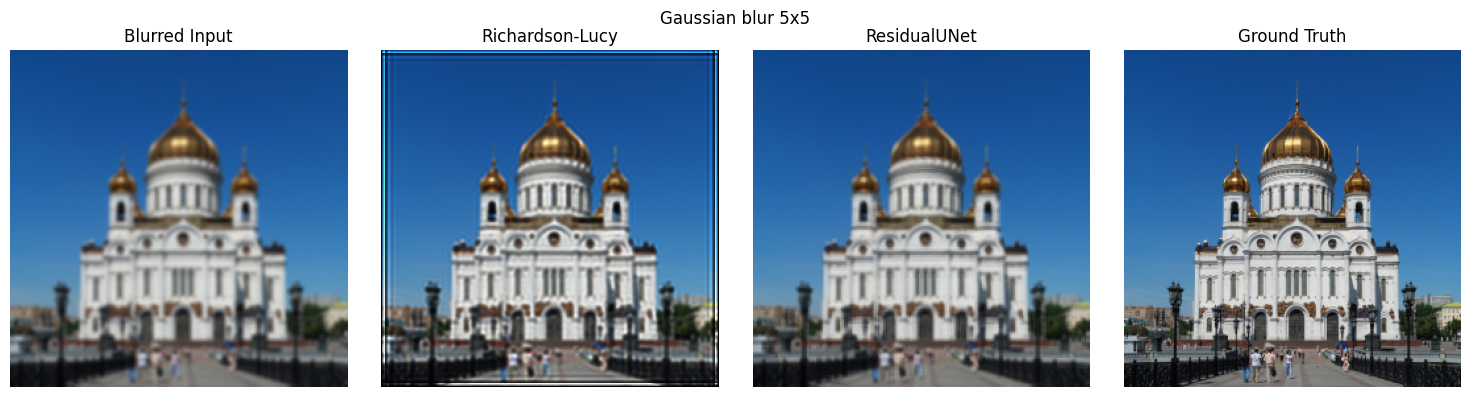

Saved 6 comparison figures


In [17]:
panel_titles = ["Blurred Input", "Richardson-Lucy", "ResidualUNet", "Ground Truth"]
panel_keys = ["input", "richardson_lucy", "residual_unet", "ground_truth"]
comparison_index = 0
for kernel_size, samples in visual_samples.items():
    for sample in samples:
        figure, axes = plt.subplots(1, 4, figsize=(15, 4))
        for axis, title, key in zip(axes, panel_titles, panel_keys):
            axis.imshow(np.clip(sample[key], 0.0, 1.0))
            axis.set_title(title)
            axis.axis("off")
        figure.suptitle(f"Gaussian blur {kernel_size}x{kernel_size}")
        figure.tight_layout()
        figure.savefig(FIGURES_DIR / f"comparison_{comparison_index + 1}.png", dpi=150, bbox_inches="tight")
        plt.show()
        plt.close(figure)
        comparison_index += 1

print(f"Saved {comparison_index} comparison figures")